# CNN Development on a Custom Dataset: Natural Scene Classification

| | |
|---|---|
| **Course** | Computer Vision and Pattern Recognition (CVPR) |
| **Student** | Saadman Sakib Saad |
| **Student ID** | 22-49179-3 |
| **Assignment** | CNN Development on Custom Dataset (10 marks) |
| **Dataset** | Intel Image Classification (Kaggle, 6 classes) |
| **Framework** | PyTorch |

## Overview
In this notebook I design, train and evaluate a **custom CNN built from scratch** (no pretrained weights) to classify natural-scene photographs into six categories: *buildings, forest, glacier, mountain, sea, street*.

**Pipeline:** load data → explore → preprocess and augment → define CNN → train with validation → evaluate on the held-out test set → visualise curves → analyse and discuss → conclusions.

> **How to run:** open in Google Colab, set *Runtime → Change runtime type → GPU (T4)*, then *Runtime → Run all*. The dataset is downloaded automatically. Total runtime is roughly 10 to 20 minutes on a T4.

## 1. Import Libraries and Global Configuration
All hyperparameters live in one `CONFIG` dictionary so that every experiment setting is visible in one place. The reasoning for each value is given in the table in Section 5.

In [1]:
import os, sys, time, json, copy, random, subprocess
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

sns.set_theme(style="whitegrid", context="notebook")

# ---------------- Hyperparameters (rationale in Section 5) ----------------
CONFIG = dict(
    seed         = 42,
    img_size     = 128,      # images are 150x150 natively; 128 keeps detail and is fast
    batch_size   = 64,
    epochs       = 30,       # upper bound, early stopping usually ends sooner
    lr           = 1e-3,
    weight_decay = 1e-4,
    val_fraction = 0.15,     # stratified split taken from the official training folder
    es_patience  = 7,        # early stopping on validation accuracy
    lr_factor    = 0.5,      # ReduceLROnPlateau
    lr_patience  = 2,
    num_workers  = 2,
)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(CONFIG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("PyTorch :", torch.__version__)
print("Device  :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (training will be slow, switch to a GPU runtime)")

PyTorch : 2.14.1+cu130
Device  : cuda | Tesla T4


## 2. Load and Explore the Dataset

### 2.1 Dataset description
| Property | Value |
|---|---|
| **Name** | Intel Image Classification |
| **Source** | Kaggle: `puneet6060/intel-image-classification` (originally released by Intel for an Analytics Vidhya challenge). Mirrored on Hugging Face as `sfarrukhm/intel-image-classification`. |
| **Task** | Multi-class image classification of natural scenes |
| **Classes (6)** | buildings, forest, glacier, mountain, sea, street |
| **Image size** | 150 x 150 RGB (JPEG) |
| **Split sizes** | about 14,000 train, about 3,000 test, about 7,000 unlabeled "prediction" images (not used here) |
| **Why this dataset** | Six visually distinct but partly overlapping classes (e.g. glacier vs mountain, buildings vs street) make it a good test for a from-scratch CNN, and the dataset is large enough to train without pretraining. |

The loader below tries Kaggle first, then falls back to the Hugging Face mirror. If both fail (no internet), upload the dataset and set `DATA_DIR` manually.

In [2]:
DATA_DIR = None   # optional: set to a folder that contains seg_train / seg_test if you downloaded the data yourself

def find_roots(base):
    # Locate the folders that hold the class sub-folders (handles the double-nested Kaggle layout).
    train_root = test_root = None
    for dirpath, dirnames, _ in os.walk(base):
        if "buildings" in dirnames:
            p = dirpath.lower()
            if "seg_train" in p:
                train_root = dirpath
            elif "seg_test" in p:
                test_root = dirpath
    return train_root, test_root

def download_dataset():
    # 1) Kaggle via kagglehub
    try:
        try:
            import kagglehub
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        path = kagglehub.dataset_download("puneet6060/intel-image-classification")
        if all(find_roots(path)):
            print("Downloaded from Kaggle.")
            return path
    except Exception as e:
        print("Kaggle download failed:", repr(e)[:200])
    # 2) Hugging Face mirror (raw files, no loading script needed)
    try:
        from huggingface_hub import snapshot_download
        path = snapshot_download(repo_id="sfarrukhm/intel-image-classification", repo_type="dataset")
        if all(find_roots(path)):
            print("Downloaded from Hugging Face.")
            return path
    except Exception as e:
        print("Hugging Face download failed:", repr(e)[:200])
    raise RuntimeError("Could not download the dataset. Upload it manually and set DATA_DIR.")

base_path = DATA_DIR if DATA_DIR else download_dataset()
TRAIN_ROOT, TEST_ROOT = find_roots(base_path)
print("Train folder:", TRAIN_ROOT)
print("Test folder :", TEST_ROOT)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Downloaded from Kaggle.
Train folder: /kaggle/input/intel-image-classification/seg_train/seg_train
Test folder : /kaggle/input/intel-image-classification/seg_test/seg_test


### 2.2 Class distribution, image sizes and samples
Checking class balance matters because it decides whether plain accuracy is a trustworthy metric, and checking image sizes confirms that a fixed resize is safe.

,class,train,test
0,buildings,2191,437
1,forest,2271,474
2,glacier,2404,553
3,mountain,2512,525
4,sea,2274,510
5,street,2382,501
6,TOTAL,14034,3000


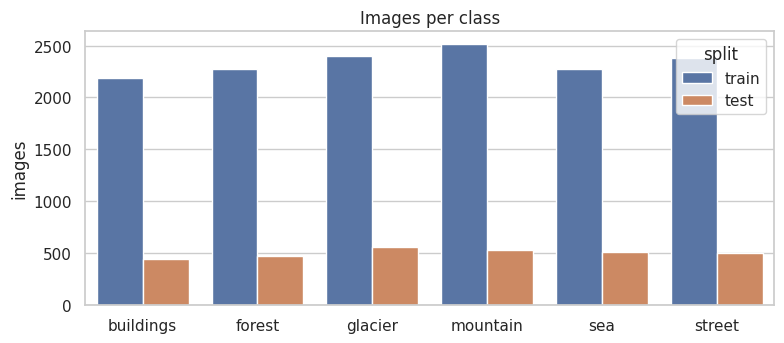

Image sizes found in a random sample of 300: {(150, 150): 298, (150, 111): 1, (150, 108): 1}


In [3]:
explore_train = datasets.ImageFolder(TRAIN_ROOT)
explore_test  = datasets.ImageFolder(TEST_ROOT)
CLASSES = explore_train.classes
NUM_CLASSES = len(CLASSES)
assert explore_train.class_to_idx == explore_test.class_to_idx, "train/test class order mismatch"

df_counts = pd.DataFrame({
    "class": CLASSES,
    "train": np.bincount(explore_train.targets, minlength=NUM_CLASSES),
    "test":  np.bincount(explore_test.targets,  minlength=NUM_CLASSES),
})
df_counts.loc[len(df_counts)] = ["TOTAL", df_counts["train"].sum(), df_counts["test"].sum()]
display(df_counts)

fig, ax = plt.subplots(figsize=(8, 3.6))
plot_df = df_counts.iloc[:-1].melt(id_vars="class", var_name="split", value_name="images")
sns.barplot(data=plot_df, x="class", y="images", hue="split", ax=ax)
ax.set_title("Images per class"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

rng = random.Random(CONFIG["seed"])
all_paths = [p for p, _ in explore_train.samples]
sample_paths = rng.sample(all_paths, min(300, len(all_paths)))
size_counts = Counter(Image.open(p).size for p in sample_paths)
print(f"Image sizes found in a random sample of {len(sample_paths)}:", dict(size_counts))

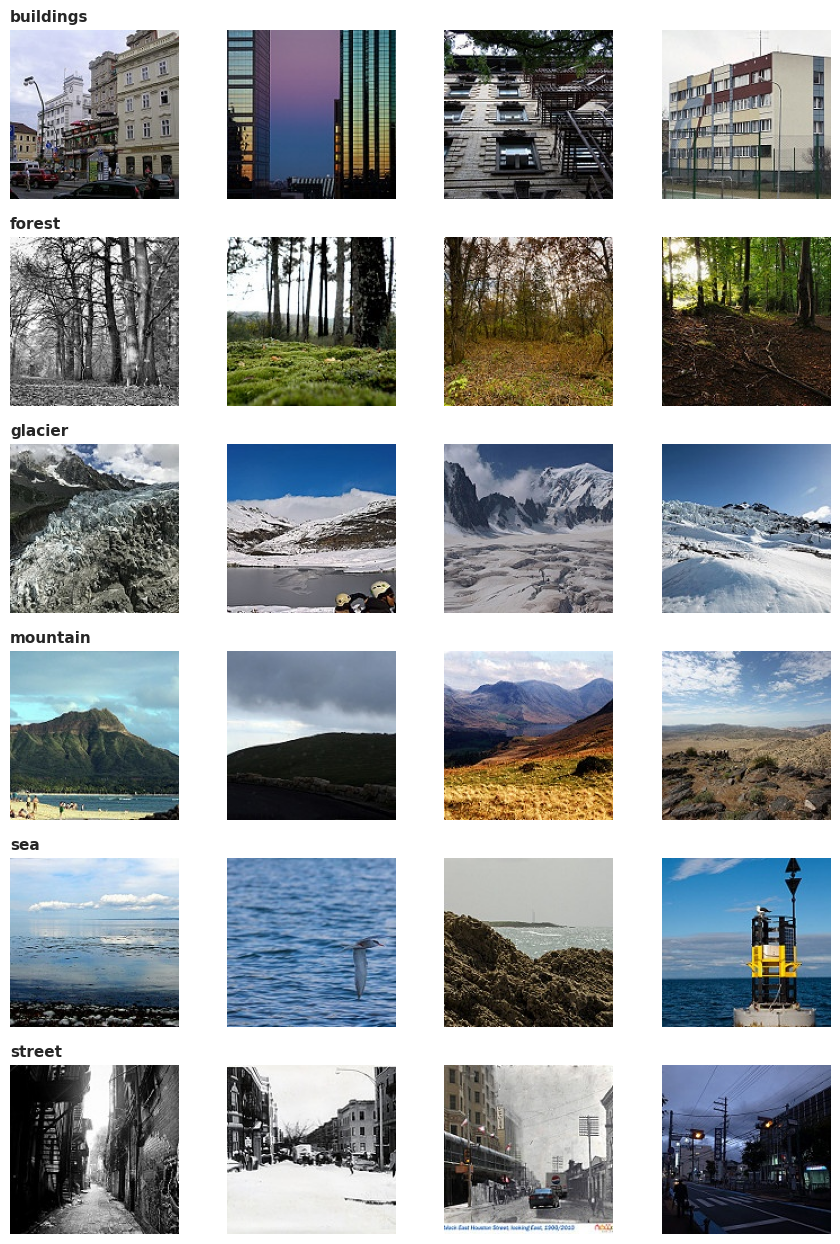

In [4]:
# 4 random training images per class
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(9, 2.1 * NUM_CLASSES))
for c, cls in enumerate(CLASSES):
    paths = [p for p, t in explore_train.samples if t == c]
    for j, p in enumerate(rng.sample(paths, 4)):
        axes[c, j].imshow(Image.open(p).convert("RGB")); axes[c, j].axis("off")
        if j == 0:
            axes[c, j].set_title(cls, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 3. Data Preprocessing and Augmentation

**Splits.** The dataset ships with a training and a test folder. I keep the **test folder completely untouched** until the final evaluation and carve a **stratified 85/15 validation split** out of the training folder. Validation is used for model selection (early stopping, LR scheduling, best checkpoint); test is used once.

**Preprocessing.**
1. Resize to `128 x 128`.
2. Convert to tensor (scales pixels to [0, 1]).
3. Normalise each channel with the **mean and std computed on the training split only** (no leakage from validation or test).

**Augmentation (training only).** Random resized crop (scale 0.7 to 1.0), horizontal flip, rotation up to 10 degrees and mild colour jitter. Scenes are not orientation-sensitive in a way that flips would break (a mirrored forest is still a forest), while lighting and framing vary a lot between photos, so these transforms mimic real variation and fight overfitting. Vertical flips are deliberately *not* used because skies and ground have a fixed vertical order in natural scenes.

In [5]:
IMG = CONFIG["img_size"]

# ---- stratified train / validation split on indices ----
full_for_split = datasets.ImageFolder(TRAIN_ROOT)
targets = np.array(full_for_split.targets)
train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=CONFIG["val_fraction"],
    stratify=targets, random_state=CONFIG["seed"])
print(f"Train: {len(train_idx)} | Validation: {len(val_idx)} | Test: {len(explore_test)}")

# ---- channel mean / std from the TRAINING split only ----
raw_tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor()])
stat_ds = Subset(datasets.ImageFolder(TRAIN_ROOT, transform=raw_tf), train_idx)
stat_loader = DataLoader(stat_ds, batch_size=256, shuffle=False, num_workers=CONFIG["num_workers"])
s1 = torch.zeros(3); s2 = torch.zeros(3); npix = 0
for xb, _ in stat_loader:
    s1 += xb.sum(dim=(0, 2, 3)); s2 += (xb ** 2).sum(dim=(0, 2, 3)); npix += xb.numel() // 3
MEAN = (s1 / npix); STD = ((s2 / npix) - MEAN ** 2).sqrt()
print("Train mean:", [round(v, 4) for v in MEAN.tolist()], "| std:", [round(v, 4) for v in STD.tolist()])

# ---- transforms ----
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN.tolist(), STD.tolist()),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN.tolist(), STD.tolist()),
])

# ---- datasets: same files, different transforms for train vs validation ----
train_ds = Subset(datasets.ImageFolder(TRAIN_ROOT, transform=train_tf), train_idx)
val_ds   = Subset(datasets.ImageFolder(TRAIN_ROOT, transform=eval_tf),  val_idx)
test_ds  = datasets.ImageFolder(TEST_ROOT, transform=eval_tf)

# ---- data loaders ----
def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

g = torch.Generator(); g.manual_seed(CONFIG["seed"])
loader_kw = dict(batch_size=CONFIG["batch_size"], num_workers=CONFIG["num_workers"],
                 pin_memory=(device.type == "cuda"), worker_init_fn=seed_worker,
                 persistent_workers=CONFIG["num_workers"] > 0)
train_loader = DataLoader(train_ds, shuffle=True, generator=g, drop_last=False, **loader_kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **loader_kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **loader_kw)

xb, yb = next(iter(train_loader))
print(f"One training batch -> images {tuple(xb.shape)}, labels {tuple(yb.shape)}, "
      f"pixel range after normalisation [{xb.min():.2f}, {xb.max():.2f}]")
print("Batches per epoch: train", len(train_loader), "| val", len(val_loader), "| test", len(test_loader))

Train: 11928 | Validation: 2106 | Test: 3000
Train mean: [0.4303, 0.4575, 0.4538] | std: [0.2576, 0.2561, 0.2884]
One training batch -> images (64, 3, 128, 128), labels (64,), pixel range after normalisation [-1.79, 2.21]
Batches per epoch: train 187 | val 33 | test 47


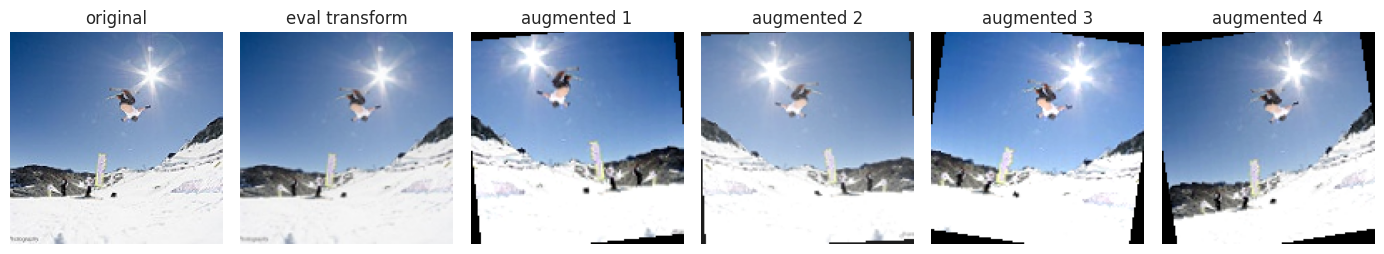

In [6]:
# Visual check of the augmentation pipeline on one training image
def denorm(t):
    return (t * STD.view(3, 1, 1) + MEAN.view(3, 1, 1)).clamp(0, 1)

path0 = explore_train.samples[int(train_idx[0])][0]
orig = Image.open(path0).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
axes[0].imshow(orig); axes[0].set_title("original"); axes[0].axis("off")
axes[1].imshow(denorm(eval_tf(orig)).permute(1, 2, 0)); axes[1].set_title("eval transform"); axes[1].axis("off")
for k in range(2, 6):
    axes[k].imshow(denorm(train_tf(orig)).permute(1, 2, 0)); axes[k].set_title(f"augmented {k-1}"); axes[k].axis("off")
plt.tight_layout(); plt.show()

## 4. Define the CNN Architecture

I use a compact **VGG-style network ("IntelNet")** with four convolutional stages followed by a small classifier head.

| Stage | Layers | Output shape (C x H x W) |
|---|---|---|
| Input | RGB image | 3 x 128 x 128 |
| Block 1 | 2 x [Conv3x3, BatchNorm, ReLU], MaxPool 2x2, Dropout2d | 32 x 64 x 64 |
| Block 2 | same, 64 channels | 64 x 32 x 32 |
| Block 3 | same, 128 channels | 128 x 16 x 16 |
| Block 4 | same, 256 channels | 256 x 8 x 8 |
| Head | Global Average Pooling, Linear(256, 256), ReLU, Dropout(0.4), Linear(256, 6) | 6 logits |

**Design justification**
- **Two stacked 3x3 convolutions per block** give the same receptive field as a 5x5 kernel with fewer parameters and an extra non-linearity (the VGG idea).
- **Channels double as resolution halves** (32 → 64 → 128 → 256): early layers learn a few simple features (edges, colour blobs) at high resolution, deeper layers learn many richer, more abstract features (textures, shapes) at low resolution, keeping compute per stage balanced.
- **Batch Normalisation** stabilises and speeds up training and permits a higher learning rate. Convolutions use `bias=False` because BN's shift makes the bias redundant.
- **Dropout2d with a small rate that grows with depth, plus Dropout(0.4) in the head** regularise the network where overfitting risk is highest (deeper, wider layers).
- **Global Average Pooling instead of flattening.** Flattening 256 x 8 x 8 into a dense layer would add about 4.2 million parameters, while GAP adds none and makes the model less sensitive to where in the image a feature appears.
- **Kaiming (He) initialisation** matches ReLU activations and avoids vanishing or exploding signals at the start of training.
- The whole model has roughly **1.2 million parameters (about 5 MB)**: large enough for this task, small enough to train from scratch in minutes and to fit comfortably under the 20 MB upload limit.

In [7]:
class ConvBlock(nn.Module):
    # [Conv3x3 -> BN -> ReLU] x 2 -> MaxPool(2) -> Dropout2d
    def __init__(self, c_in, c_out, p_drop):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c_in,  c_out, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(p_drop),
        )
    def forward(self, x):
        return self.block(x)


class IntelNet(nn.Module):
    def __init__(self, num_classes=6, widths=(32, 64, 128, 256),
                 block_drop=(0.05, 0.10, 0.15, 0.20), head_drop=0.4):
        super().__init__()
        chans = (3,) + tuple(widths)
        self.features = nn.Sequential(*[ConvBlock(chans[i], chans[i + 1], block_drop[i])
                                        for i in range(len(widths))])
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(widths[-1], 256), nn.ReLU(inplace=True),
            nn.Dropout(head_drop),
            nn.Linear(256, num_classes),
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu"); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


model = IntelNet(num_classes=NUM_CLASSES).to(device)
n_params = sum(p.numel() for p in model.parameters())
n_train_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters    : {n_params:,}")
print(f"Trainable parameters: {n_train_params:,}")
print(f"Approx. size (fp32) : {n_params * 4 / 1e6:.2f} MB")

Total parameters    : 1,240,550
Trainable parameters: 1,240,550
Approx. size (fp32) : 4.96 MB


In [8]:
# Detailed architecture summary (layer, output shape, parameters)
try:
    from torchinfo import summary
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchinfo"])
    from torchinfo import summary

summary(model, input_size=(1, 3, IMG, IMG), depth=3,
        col_names=("input_size", "output_size", "num_params", "mult_adds"),
        col_width=18, row_settings=("var_names",), verbose=1)

Layer (type (var_name))                  Input Shape        Output Shape       Param #            Mult-Adds
IntelNet (IntelNet)                      [1, 3, 128, 128]   [1, 6]             --                 --
├─Sequential (features)                  [1, 3, 128, 128]   [1, 256, 8, 8]     --                 --
│    └─ConvBlock (0)                     [1, 3, 128, 128]   [1, 32, 64, 64]    --                 --
│    │    └─Sequential (block)           [1, 3, 128, 128]   [1, 32, 64, 64]    10,208             165,150,848
│    └─ConvBlock (1)                     [1, 32, 64, 64]    [1, 64, 32, 32]    --                 --
│    │    └─Sequential (block)           [1, 32, 64, 64]    [1, 64, 32, 32]    55,552             226,492,672
│    └─ConvBlock (2)                     [1, 64, 32, 32]    [1, 128, 16, 16]   --                 --
│    │    └─Sequential (block)           [1, 64, 32, 32]    [1, 128, 16, 16]   221,696            226,492,928
│    └─ConvBlock (3)                     [1, 128, 16, 16]

Layer (type (var_name))                  Input Shape        Output Shape       Param #            Mult-Adds
IntelNet (IntelNet)                      [1, 3, 128, 128]   [1, 6]             --                 --
├─Sequential (features)                  [1, 3, 128, 128]   [1, 256, 8, 8]     --                 --
│    └─ConvBlock (0)                     [1, 3, 128, 128]   [1, 32, 64, 64]    --                 --
│    │    └─Sequential (block)           [1, 3, 128, 128]   [1, 32, 64, 64]    10,208             165,150,848
│    └─ConvBlock (1)                     [1, 32, 64, 64]    [1, 64, 32, 32]    --                 --
│    │    └─Sequential (block)           [1, 32, 64, 64]    [1, 64, 32, 32]    55,552             226,492,672
│    └─ConvBlock (2)                     [1, 64, 32, 32]    [1, 128, 16, 16]   --                 --
│    │    └─Sequential (block)           [1, 64, 32, 32]    [1, 128, 16, 16]   221,696            226,492,928
│    └─ConvBlock (3)                     [1, 128, 16, 16]

## 5. Training Loop with Validation

### 5.1 Hyperparameters and rationale

In [9]:
hp = pd.DataFrame([
    ("Loss", "CrossEntropyLoss", "Standard loss for multi-class classification: softmax plus negative log-likelihood, directly optimises class probabilities."),
    ("Optimizer", "AdamW (Adam with decoupled weight decay)", "Adaptive per-parameter learning rates converge quickly and need little tuning; decoupled weight decay regularises more cleanly than L2 inside Adam."),
    ("Learning rate", CONFIG["lr"], "1e-3 is the well-tested default for Adam; BatchNorm makes training tolerant of this rate."),
    ("Weight decay", CONFIG["weight_decay"], "Light regularisation to discourage large weights."),
    ("LR scheduler", f"ReduceLROnPlateau (x{CONFIG['lr_factor']}, patience {CONFIG['lr_patience']})", "Starts fast, then halves the LR when validation loss stalls to fine-tune into a sharper minimum."),
    ("Batch size", CONFIG["batch_size"], "Good balance of gradient noise (helps generalisation) and GPU efficiency; fits easily in memory."),
    ("Epochs (max)", CONFIG["epochs"], "Upper bound; early stopping decides the real length."),
    ("Early stopping", f"patience {CONFIG['es_patience']} on val accuracy", "Stops when validation stops improving and restores the best weights, preventing overfitting."),
    ("Input size", f"{IMG}x{IMG}", "Close to the native 150x150, cheaper than full size, divisible by 2 four times for the four pooling stages."),
    ("Validation split", f"{int(CONFIG['val_fraction']*100)}% stratified", "Keeps class proportions identical to training; the test set stays untouched."),
    ("Augmentation", "crop, flip, rotation, colour jitter", "Simulates natural variation in framing and lighting (see Section 3)."),
    ("Seed", CONFIG["seed"], "Reproducibility of splits, initialisation and shuffling."),
], columns=["Hyperparameter", "Value", "Rationale"])
pd.set_option("display.max_colwidth", None)
display(hp.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Hyperparameter,Value,Rationale
Loss,CrossEntropyLoss,"Standard loss for multi-class classification: softmax plus negative log-likelihood, directly optimises class probabilities."
Optimizer,AdamW (Adam with decoupled weight decay),Adaptive per-parameter learning rates converge quickly and need little tuning; decoupled weight decay regularises more cleanly than L2 inside Adam.
Learning rate,0.001000,1e-3 is the well-tested default for Adam; BatchNorm makes training tolerant of this rate.
Weight decay,0.000100,Light regularisation to discourage large weights.
LR scheduler,"ReduceLROnPlateau (x0.5, patience 2)","Starts fast, then halves the LR when validation loss stalls to fine-tune into a sharper minimum."
Batch size,64,Good balance of gradient noise (helps generalisation) and GPU efficiency; fits easily in memory.
Epochs (max),30,Upper bound; early stopping decides the real length.
Early stopping,patience 7 on val accuracy,"Stops when validation stops improving and restores the best weights, preventing overfitting."
Input size,128x128,"Close to the native 150x150, cheaper than full size, divisible by 2 four times for the four pooling stages."
Validation split,15% stratified,Keeps class proportions identical to training; the test set stays untouched.


### 5.2 Training and validation
Each epoch runs one pass over the training set (weights update, dropout and augmentation active) and one pass over the validation set (no gradient, dropout off). The weights of the epoch with the **best validation accuracy** are kept and restored at the end.

In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=CONFIG["lr_factor"], patience=CONFIG["lr_patience"])

def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb = xb.to(device, non_blocking=True); yb = yb.to(device, non_blocking=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * xb.size(0)
            correct    += (logits.argmax(1) == yb).sum().item()
            n          += xb.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
best_val_acc, best_epoch, best_state, wait = 0.0, 0, None, 0
t_start = time.time()

print(f"{'Epoch':>5} | {'Train loss':>10} {'Train acc':>9} | {'Val loss':>8} {'Val acc':>8} | {'LR':>8} | {'Time':>5}")
print("-" * 72)
for epoch in range(1, CONFIG["epochs"] + 1):
    t0 = time.time()
    lr_now = optimizer.param_groups[0]["lr"]
    tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader)
    scheduler.step(va_loss)

    for k, v in zip(history.keys(), (tr_loss, va_loss, tr_acc, va_acc, lr_now)):
        history[k].append(v)

    improved = va_acc > best_val_acc + 1e-4
    if improved:
        best_val_acc, best_epoch, wait = va_acc, epoch, 0
        best_state = copy.deepcopy(model.state_dict())
    else:
        wait += 1

    print(f"{epoch:>5} | {tr_loss:>10.4f} {tr_acc:>9.4f} | {va_loss:>8.4f} {va_acc:>8.4f} | {lr_now:>8.1e} | {time.time()-t0:>4.0f}s {'*' if improved else ''}")
    if wait >= CONFIG["es_patience"]:
        print(f"Early stopping at epoch {epoch} (no validation improvement for {CONFIG['es_patience']} epochs).")
        break

model.load_state_dict(best_state)
print(f"\nTraining time: {(time.time()-t_start)/60:.1f} min | best epoch: {best_epoch} | best validation accuracy: {best_val_acc:.4f}")

Epoch | Train loss Train acc | Val loss  Val acc |       LR |  Time
------------------------------------------------------------------------
    1 |     1.2010    0.5057 |   0.9213   0.6173 |  1.0e-03 |   56s *
    2 |     0.9262    0.6405 |   0.7066   0.7379 |  1.0e-03 |   40s *
    3 |     0.7912    0.6995 |   0.6052   0.7811 |  1.0e-03 |   39s *
    4 |     0.7242    0.7302 |   0.5841   0.7877 |  1.0e-03 |   39s *
    5 |     0.6723    0.7547 |   0.6263   0.7631 |  1.0e-03 |   40s 
    6 |     0.6347    0.7706 |   0.5017   0.8253 |  1.0e-03 |   39s *
    7 |     0.6124    0.7773 |   0.4770   0.8319 |  1.0e-03 |   40s *
    8 |     0.5841    0.7889 |   0.4660   0.8314 |  1.0e-03 |   40s 
    9 |     0.5645    0.7953 |   0.4817   0.8253 |  1.0e-03 |   40s 
   10 |     0.5509    0.7993 |   0.4493   0.8433 |  1.0e-03 |   40s *
   11 |     0.5283    0.8073 |   0.4181   0.8466 |  1.0e-03 |   39s *
   12 |     0.5172    0.8106 |   0.4236   0.8538 |  1.0e-03 |   40s *
   13 |     0.5055    

## 6. Evaluate the Model on the Test Set
The test set has not been used for any decision so far, so these numbers estimate real-world performance. Besides accuracy I report **per-class precision, recall and F1**, because accuracy alone can hide a weak class.

In [11]:
@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    logits_all, labels_all = [], []
    for xb, yb in loader:
        logits_all.append(model(xb.to(device)).cpu()); labels_all.append(yb)
    logits = torch.cat(logits_all); labels = torch.cat(labels_all)
    loss = F.cross_entropy(logits, labels).item()
    probs = logits.softmax(1)
    return loss, probs.argmax(1).numpy(), labels.numpy(), probs.numpy()

test_loss, y_pred, y_true, y_prob = predict_loader(model, test_loader)
test_acc = accuracy_score(y_true, y_pred)
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc*100:.2f}%  ({(y_pred == y_true).sum()} / {len(y_true)} correct)\n")

report_txt  = classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0)
report_dict = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True, zero_division=0)
print(report_txt)

Test loss    : 0.2755
Test accuracy: 90.33%  (2710 / 3000 correct)

              precision    recall  f1-score   support

   buildings     0.9061    0.8833    0.8946       437
      forest     0.9873    0.9831    0.9852       474
     glacier     0.8385    0.8734    0.8556       553
    mountain     0.8683    0.8286    0.8480       525
         sea     0.9298    0.9353    0.9326       510
      street     0.9043    0.9242    0.9141       501

    accuracy                         0.9033      3000
   macro avg     0.9057    0.9046    0.9050      3000
weighted avg     0.9036    0.9033    0.9033      3000



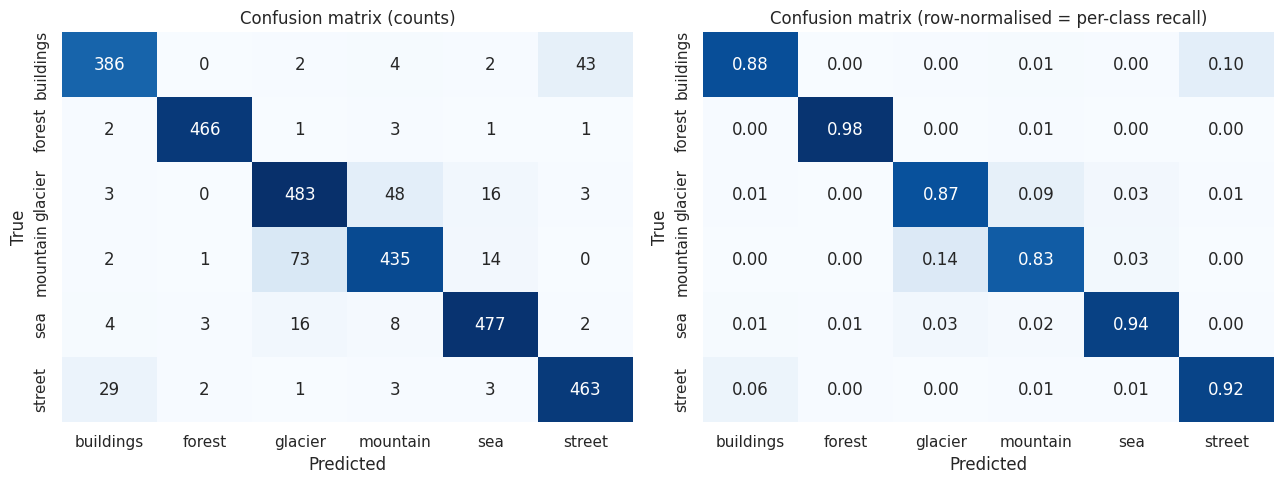

In [12]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], cbar=False)
axes[0].set_title("Confusion matrix (counts)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], cbar=False, vmin=0, vmax=1)
axes[1].set_title("Confusion matrix (row-normalised = per-class recall)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

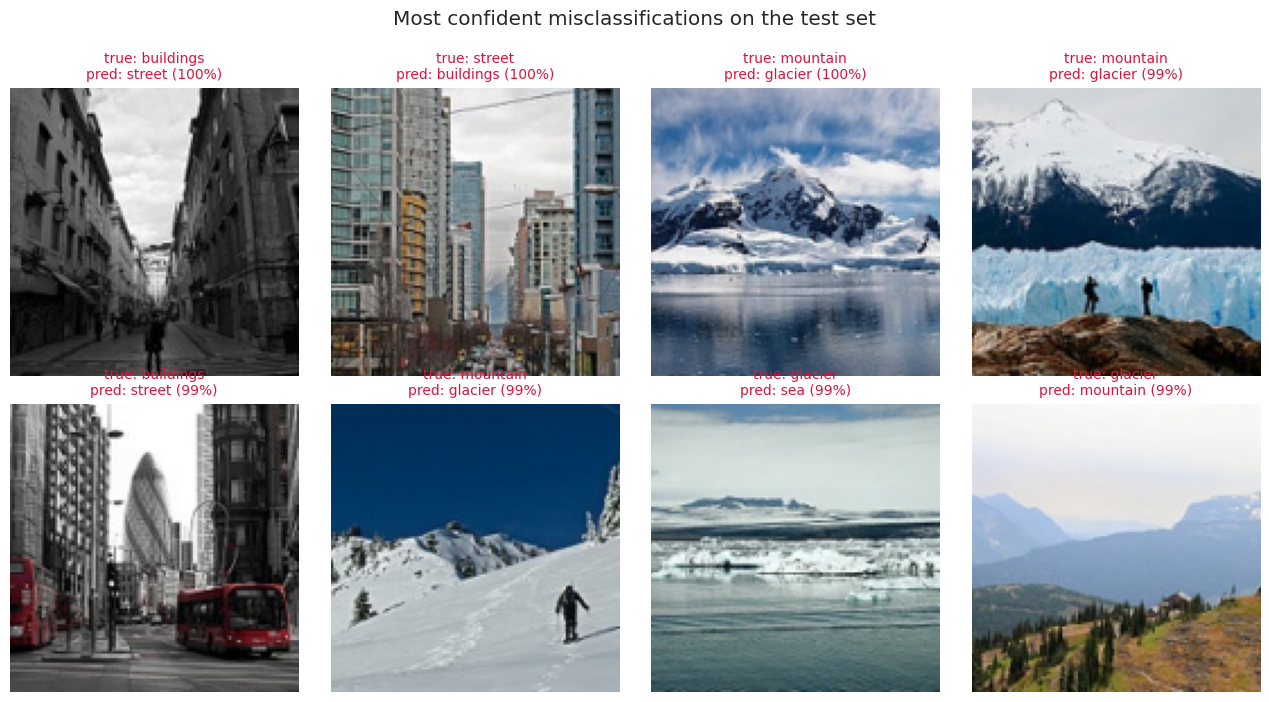

In [13]:
# The most confident mistakes: these are the most informative failures
wrong = np.where(y_pred != y_true)[0]
if len(wrong) == 0:
    print("No misclassified test images.")
else:
    conf_wrong = y_prob[wrong, y_pred[wrong]]
    show = wrong[np.argsort(-conf_wrong)][:8]
    fig, axes = plt.subplots(2, 4, figsize=(13, 7))
    for ax, i in zip(axes.ravel(), show):
        img, _ = test_ds[int(i)]
        ax.imshow(denorm(img).permute(1, 2, 0)); ax.axis("off")
        ax.set_title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({y_prob[i, y_pred[i]]:.0%})", fontsize=10, color="crimson")
    for ax in axes.ravel()[len(show):]:
        ax.axis("off")
    plt.suptitle("Most confident misclassifications on the test set", y=1.0)
    plt.tight_layout(); plt.savefig("misclassified.png", dpi=150); plt.show()

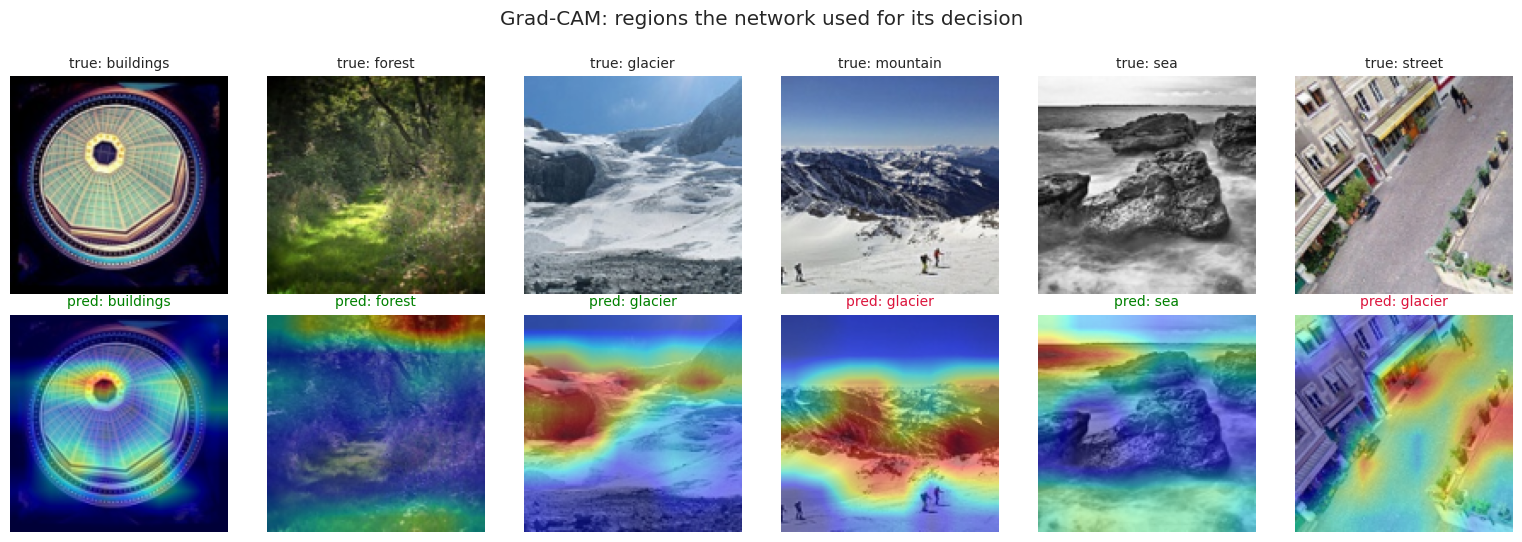

In [14]:
# Grad-CAM: which image regions drive the prediction? (computed on the last conv stage)
def grad_cam(model, x, class_idx=None):
    model.eval()
    feats = model.features(x)               # (1, C, h, w)
    feats.retain_grad()
    logits = model.classifier(model.pool(feats))
    if class_idx is None:
        class_idx = int(logits.argmax(1))
    model.zero_grad()
    logits[0, class_idx].backward()
    weights = feats.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * feats).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), class_idx

rng_np = np.random.RandomState(CONFIG["seed"])
picks = [int(rng_np.choice(np.where(y_true == c)[0])) for c in range(NUM_CLASSES)]   # one test image per class
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(2.6 * NUM_CLASSES, 5.4))
for col, i in enumerate(picks):
    img, label = test_ds[i]
    cam, pred_c = grad_cam(model, img.unsqueeze(0).to(device))
    base = denorm(img).permute(1, 2, 0).numpy()
    axes[0, col].imshow(base); axes[0, col].axis("off")
    axes[0, col].set_title(f"true: {CLASSES[label]}", fontsize=10)
    axes[1, col].imshow(base); axes[1, col].imshow(cam, cmap="jet", alpha=0.45); axes[1, col].axis("off")
    axes[1, col].set_title(f"pred: {CLASSES[pred_c]}", fontsize=10, color="green" if pred_c == label else "crimson")
plt.suptitle("Grad-CAM: regions the network used for its decision", y=1.0)
plt.tight_layout(); plt.savefig("gradcam.png", dpi=150); plt.show()

## 7. Visualisations: Loss and Accuracy Curves
Reading guide:
- **Both losses falling together** means the model is learning patterns that generalise.
- **Validation loss rising while training loss keeps falling** is the classic sign of overfitting.
- **Training accuracy below validation accuracy** is *not* a bug here: during training the network sees augmented images with dropout active, while validation uses clean images with dropout off.
- **Steps in the learning-rate curve** mark where the scheduler detected a plateau and reduced the LR, which often produces a visible drop in loss right afterwards.

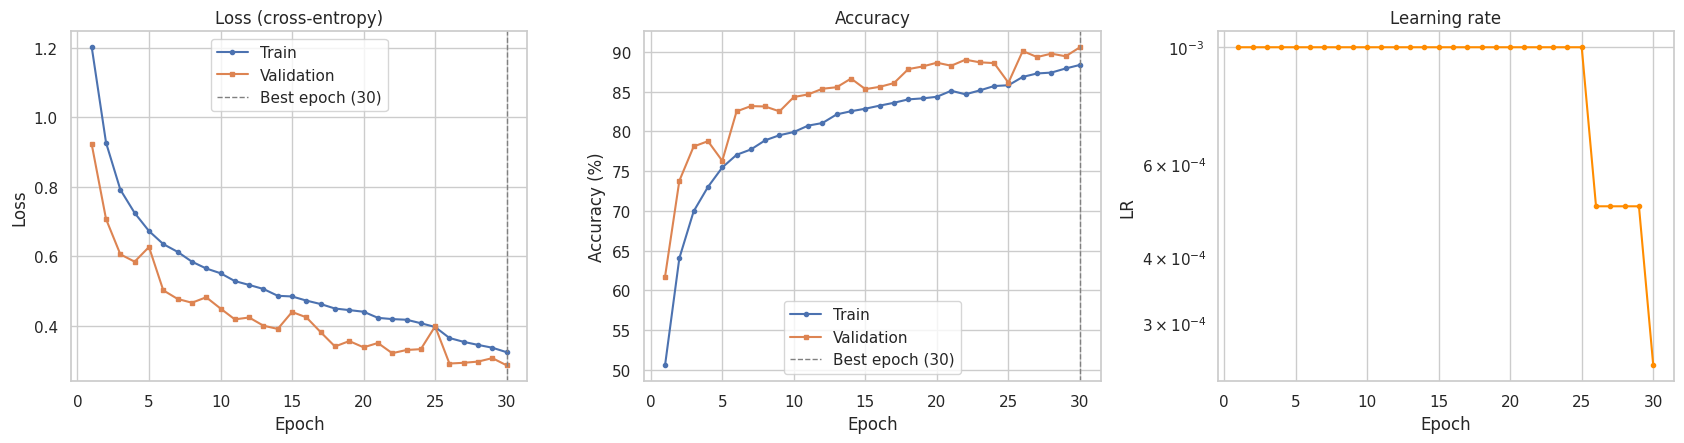

In [15]:
epochs_run = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

axes[0].plot(epochs_run, history["train_loss"], "o-", label="Train", ms=3)
axes[0].plot(epochs_run, history["val_loss"],   "s-", label="Validation", ms=3)
axes[0].axvline(best_epoch, color="gray", ls="--", lw=1, label=f"Best epoch ({best_epoch})")
axes[0].set(title="Loss (cross-entropy)", xlabel="Epoch", ylabel="Loss"); axes[0].legend()

axes[1].plot(epochs_run, np.array(history["train_acc"]) * 100, "o-", label="Train", ms=3)
axes[1].plot(epochs_run, np.array(history["val_acc"]) * 100,   "s-", label="Validation", ms=3)
axes[1].axvline(best_epoch, color="gray", ls="--", lw=1, label=f"Best epoch ({best_epoch})")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy (%)"); axes[1].legend()

axes[2].plot(epochs_run, history["lr"], "o-", color="darkorange", ms=3)
axes[2].set(title="Learning rate", xlabel="Epoch", ylabel="LR", yscale="log")

plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

## 8. Analysis and Discussion of Results

The cell below builds the discussion **from the actual numbers of this run**, so the text always matches the plots and tables above.

In [16]:
best_i = best_epoch - 1
tr_a, va_a = history["train_acc"][best_i], history["val_acc"][best_i]
tr_l, va_l = history["train_loss"][best_i], history["val_loss"][best_i]

per_class = {c: report_dict[c] for c in CLASSES}
best_cls  = max(per_class, key=lambda c: per_class[c]["f1-score"])
worst_cls = min(per_class, key=lambda c: per_class[c]["f1-score"])

pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
pairs = sorted(pairs, key=lambda t: -t[2])[:3]

lines = []
close = abs(test_acc - va_a) <= 0.02
lines.append(f"1) Performance. The model reached {test_acc*100:.2f}% accuracy on the {len(y_true)} unseen test images "
             f"(macro F1 = {report_dict['macro avg']['f1-score']:.3f}), versus {va_a*100:.2f}% on validation at the best epoch. "
             + ("The test score is within 2 points of validation, so the validation split was a trustworthy guide and model selection did not overfit it."
                if close else
                "Test and validation differ by more than 2 points, so the validation split was only a rough guide here (the test set is also a finite sample, which adds noise)."))
gap = va_a - tr_a
if gap > 0.01:
    lines.append(f"2) Fit. At the best epoch training accuracy ({tr_a*100:.2f}%) is below validation accuracy ({va_a*100:.2f}%). "
                 f"This is expected because training uses augmentation and dropout while validation does not; it indicates the model is regularised and not memorising the training set.")
elif gap < -0.05:
    lines.append(f"2) Fit. Training accuracy ({tr_a*100:.2f}%) exceeds validation accuracy ({va_a*100:.2f}%) by {abs(gap)*100:.1f} points, "
                 f"a sign of mild overfitting; stronger augmentation, more dropout or more data would be the first remedies.")
else:
    lines.append(f"2) Fit. Training ({tr_a*100:.2f}%) and validation ({va_a*100:.2f}%) accuracy are within {abs(gap)*100:.1f} points of each other, "
                 f"so the model generalises well with no meaningful overfitting.")
lines.append(f"3) Per-class behaviour. The easiest class is '{best_cls}' (F1 {per_class[best_cls]['f1-score']:.3f}) and the hardest is "
             f"'{worst_cls}' (F1 {per_class[worst_cls]['f1-score']:.3f}).")
pair_txt = "; ".join(f"{a} predicted as {b} ({n} times)" for a, b, n in pairs if n > 0)
if pair_txt:
    top_pairs = {frozenset((a, b)) for a, b, n in pairs if n > 0}
    known = [frozenset(("glacier", "mountain")), frozenset(("buildings", "street"))]
    if any(k in top_pairs for k in known):
        why = ("Glacier/mountain scenes share snow, rock and sky, and building/street scenes share facades and roads, "
               "so part of this confusion reflects genuinely ambiguous images and not only model weakness.")
    else:
        why = ("Check the misclassified examples above to see whether these pairs share visual content or whether the labels are ambiguous.")
    lines.append(f"4) Main confusions: {pair_txt}. {why} "
                 f"The Grad-CAM maps show whether the network attends to the object that defines the class or to background context.")
else:
    lines.append("4) The model made no misclassifications on the test set, so there are no confusion pairs to analyse.")
stopped_early = len(history["train_loss"]) < CONFIG["epochs"]
lines.append(f"5) Training dynamics. The best validation accuracy occurred at epoch {best_epoch} of {len(history['train_loss'])} run "
             f"({'early stopping ended training' if stopped_early else 'the full epoch budget was used'}); the learning rate went from "
             f"{history['lr'][0]:.1e} to {history['lr'][-1]:.1e} via the plateau scheduler.")
lines.append(f"6) Model cost. {n_params:,} parameters (~{n_params*4/1e6:.1f} MB), so it is small enough to deploy on modest hardware.")

for ln in lines:
    print(ln, "\n")

1) Performance. The model reached 90.33% accuracy on the 3000 unseen test images (macro F1 = 0.905), versus 90.60% on validation at the best epoch. The test score is within 2 points of validation, so the validation split was a trustworthy guide and model selection did not overfit it. 

2) Fit. At the best epoch training accuracy (88.37%) is below validation accuracy (90.60%). This is expected because training uses augmentation and dropout while validation does not; it indicates the model is regularised and not memorising the training set. 

3) Per-class behaviour. The easiest class is 'forest' (F1 0.985) and the hardest is 'mountain' (F1 0.848). 

4) Main confusions: mountain predicted as glacier (73 times); glacier predicted as mountain (48 times); buildings predicted as street (43 times). Glacier/mountain scenes share snow, rock and sky, and building/street scenes share facades and roads, so part of this confusion reflects genuinely ambiguous images and not only model weakness. The G

## 9. Conclusions and Future Work

### Conclusions
- A **custom CNN trained from scratch**, with batch normalisation, dropout, global average pooling and sensible augmentation, learns to classify six natural-scene categories without any pretrained weights (final numbers are in Sections 6 and 8).
- A **clean experimental protocol** (stratified validation split, normalisation statistics from the training split only, test set used once) makes the reported test accuracy a fair estimate of generalisation.
- **Accuracy alone is not enough**: the confusion matrix and per-class F1 reveal which scene types are intrinsically ambiguous, and Grad-CAM shows what the model actually looks at.
- At roughly 1.2 M parameters the model is light enough to train in minutes and save well under the 20 MB limit.

### Limitations
- One dataset and one random seed: results could vary by a fraction of a percent across seeds.
- Images are downscaled to 128 x 128, so very fine texture cues are lost.
- No systematic hyperparameter search; values come from well-established defaults.
- Some labels are inherently ambiguous (a scene can contain both a street and buildings), which caps achievable accuracy.

### Future work
1. **Transfer learning** (e.g. fine-tune ResNet-18 or MobileNetV2 from ImageNet) and compare against this scratch model.
2. **Stronger regularisation and augmentation**: MixUp or CutMix, label smoothing, test-time augmentation.
3. **Better schedules and search**: One-Cycle or cosine LR schedule and a small Bayesian search over width, dropout and learning rate.
4. **Multiple seeds or an ensemble** to report mean and standard deviation and gain a few extra points.
5. **Error analysis and label cleaning** on the most confident mistakes shown above.

## 10. Save and Reload the Trained Model
Two files are written:
- `intelnet_best.pth`: the **state_dict only** (the standard, portable way to save PyTorch weights, and the file to upload to GitHub).
- `intelnet_checkpoint.pth`: weights plus class names, normalisation statistics, config and training history, which is everything needed to run inference later.

The model is then **reloaded into a fresh network and re-evaluated** to prove the saved file reproduces the same test accuracy.

In [17]:
MODEL_PATH = "intelnet_best.pth"
CKPT_PATH  = "intelnet_checkpoint.pth"

torch.save(model.state_dict(), MODEL_PATH)
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": CLASSES,
    "mean": MEAN.tolist(), "std": STD.tolist(),
    "img_size": IMG, "config": CONFIG,
    "best_epoch": best_epoch, "best_val_acc": best_val_acc, "test_acc": test_acc,
    "history": history,
}, CKPT_PATH)

for p in (MODEL_PATH, CKPT_PATH):
    print(f"{p:<26} {os.path.getsize(p)/1e6:6.2f} MB")
size_mb = os.path.getsize(MODEL_PATH) / 1e6
print("\nUnder the 20 MB limit: safe to upload to GitHub." if size_mb < 20 else "\nOver 20 MB: keep a local copy, do NOT upload to GitHub.")

# ---- reload into a brand-new model and verify ----
reloaded = IntelNet(num_classes=NUM_CLASSES).to(device)
reloaded.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
_, y_pred2, y_true2, _ = predict_loader(reloaded, test_loader)
acc2 = accuracy_score(y_true2, y_pred2)
print(f"\nTest accuracy of reloaded model: {acc2*100:.2f}%  (original: {test_acc*100:.2f}%)")
assert abs(acc2 - test_acc) < 1e-9, "Reloaded model does not reproduce the original accuracy"
print("Save and load verified.")

intelnet_best.pth            4.99 MB
intelnet_checkpoint.pth      4.99 MB

Under the 20 MB limit: safe to upload to GitHub.

Test accuracy of reloaded model: 90.33%  (original: 90.33%)
Save and load verified.


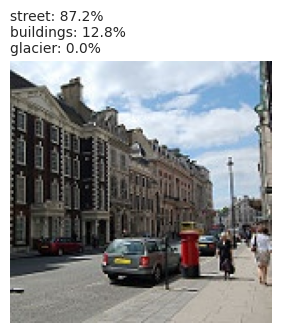

File: /kaggle/input/intel-image-classification/seg_test/seg_test/street/22017.jpg


In [18]:
# Inference helper: classify any single image file with the saved model
def predict_image(path, model=reloaded, top_k=3):
    img = Image.open(path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = model(x).softmax(1)[0].cpu()
    vals, idxs = probs.topk(top_k)
    return img, [(CLASSES[i], float(v)) for v, i in zip(vals, idxs)]

demo_path = explore_test.samples[int(np.random.RandomState(0).randint(len(explore_test.samples)))][0]
img, top = predict_image(demo_path)
plt.figure(figsize=(3.4, 3.4)); plt.imshow(img); plt.axis("off")
plt.title("\n".join(f"{c}: {p:.1%}" for c, p in top), fontsize=10, loc="left"); plt.show()
print("File:", demo_path)

# Optional (Colab only): download the artefacts to your computer
try:
    from google.colab import files
    # files.download(MODEL_PATH)      # uncomment to download the weights
    # files.download("training_curves.png")
except ImportError:
    pass